# TRACE &mdash; One-notebook reproduction

**Paper:** TRACE &mdash; Targeted Ranking-Aware Counterfactual Explanation for Sequential Recommendation (anonymous submission, RecSys 2026).

This notebook is the single entry point for reviewers. It reads only `results/paper_numbers.json` and pre-rendered figures from `figures/`, so it runs in seconds on any Python 3.9+ environment that has `pandas` and `matplotlib`. No GPU, no model download, no dataset download is required. The sections below mirror the paper exactly:

1. Method overview &mdash; Algorithm 1
2. Backbones &mdash; Table 1 (HR@10 / NDCG@10 on five datasets)
3. Main results: bring-in and push-out &mdash; Figure 1 (triplet) + Table 3 ($\Delta$NLL)
4. Ablation &mdash; Table 4 (bring-in validity) + Table 5 (push-out Q / $\Delta$NLL)
5. Significance &mdash; consolidated paired-test summary
6. Qualitative case studies &mdash; three hand-picked users
7. Hyperparameters &amp; dataset statistics

The raw per-seed JSONs that these numbers were aggregated from are regenerable with `scripts/reproduce_main.sh`; they total several gigabytes and are therefore not shipped.

## 0. (Optional) Re-run the pipeline from scratch

By default every cell below reads pre-computed `results/paper_numbers.json` and `figures/*.png` so the notebook renders without a GPU. If you have the 15 trained backbones in `./checkpoints/` (or want to regenerate further upstream), set `RUN_PIPELINE = True` in the next cell and pick a Make target:

| `PIPELINE_TARGET` | What it does | Approx. cost |
|---|---|---|
| `"figures"` | Redraw PNG/PDF from existing `paper_numbers.json` | seconds |
| `"paper_numbers figures"` | Re-assemble `paper_numbers.json` then redraw | seconds |
| `"aggregate tables stats ablation_tables paper_numbers figures"` | Re-aggregate existing per-seed JSON onwards | minutes |
| `"explain_main explain_ablation aggregate tables stats ablation_tables paper_numbers figures"` | Re-run all explainers (requires trained backbones) | many hours on 1 GPU |
| `"all"` | Full pipeline: data $\to$ train $\to$ explain $\to$ tables $\to$ figures | days on 1 GPU |

The runner shells out to `make <target> PY=<current kernel>` so it re-uses this notebook's Python environment.

In [1]:
import shlex, subprocess, sys

RUN_PIPELINE   = False                        # flip to True to regenerate artifacts via Makefile
PIPELINE_TARGET = "paper_numbers figures"    # space-separated Make targets (see table above)

if RUN_PIPELINE:
    py_bin = shlex.quote(sys.executable)
    for tgt in PIPELINE_TARGET.split():
        cmd = f"make {tgt} PY={py_bin}"
        print(f"$ {cmd}", flush=True)
        subprocess.run(cmd, shell=True, check=True)
    print("\n[done] pipeline finished; downstream cells will now read the regenerated artifacts.")
else:
    print("Skipping pipeline run. Set RUN_PIPELINE=True above to regenerate artifacts.")

Skipping pipeline run. Set RUN_PIPELINE=True above to regenerate artifacts.


In [2]:
import json, os
from pathlib import Path
import pandas as pd
from IPython.display import Image, Markdown, display

pd.set_option('display.float_format', lambda x: f'{x:.4f}' if isinstance(x, float) else str(x))
ROOT = Path('.').resolve()
FIG_DIR = ROOT / 'figures'
with open(ROOT / 'results' / 'paper_numbers.json') as f:
    P = json.load(f)
print('Loaded paper_numbers.json with sections:', list(P))

Loaded paper_numbers.json with sections: ['backbone', 'delta_nll_main', 'ablation_bringin_validity', 'ablation_pushout_efficiency', 'significance_summary', 'hyperparameters', 'datasets', 'case_studies']


## 1. Method overview

TRACE decomposes the counterfactual search into three stages: (a) influence-guided position opening, (b) plausibility-aware candidate retrieval that blends context score, target-similarity and source-similarity signals, (c) actual-margin beam pruning. The search is embedding-accessible and training-free &mdash; only score queries and pre-trained item embeddings are used; model weights and gradients are **not** required. See Algorithm 1 and Section 4 of the paper for the full formulation.

## 2. Backbone recommendation quality (Table 1)

Three standard sequential recommenders (SASRec, BERT4Rec, GRU4Rec) are trained on five datasets under 5-core filtering and leave-one-out evaluation. TRACE operates on the frozen backbones below.

In [3]:
# Table 1 is reproduced live: load the checkpoint for each of the 15
# (model, dataset) combinations, run the forward pass on the held-out test
# split, and aggregate HR@10 / NDCG@10. Regenerate with:
#
#     python eval_backbones.py
#
# which writes results/backbone_eval.json (also shipped here so the notebook
# renders without a GPU). If the file is absent the cell falls back to the
# paper_numbers.json snapshot and flags that it did so.
import json
from pathlib import Path
import pandas as pd

BE_PATH = ROOT / 'results' / 'backbone_eval.json'
DATASETS_DISPLAY = ['ml-100k', 'ml-1m', 'steam', 'beauty', 'sports']
MODEL_DISPLAY = {'sasrec': 'SASRec', 'bert4rec': 'BERT4Rec', 'gru4rec': 'GRU4Rec'}
DATASET_DISPLAY = {'ml-100k': 'ML-100K', 'ml-1m': 'ML-1M', 'steam': 'Steam', 'beauty': 'Beauty', 'sports': 'Sports'}

def _render_live(payload):
    models = payload['models']
    rows_hr, rows_ndcg = {}, {}
    for m_key, m_label in MODEL_DISPLAY.items():
        m_rec = models.get(m_key, {})
        rows_hr[m_label]   = [m_rec.get(d, {}).get('hr10') for d in DATASETS_DISPLAY]
        rows_ndcg[m_label] = [m_rec.get(d, {}).get('ndcg10') for d in DATASETS_DISPLAY]
    cols = [DATASET_DISPLAY[d] for d in DATASETS_DISPLAY]
    return pd.DataFrame(rows_hr, index=cols).T, pd.DataFrame(rows_ndcg, index=cols).T

if BE_PATH.exists():
    payload = json.load(open(BE_PATH))
    hr, ndcg = _render_live(payload)
    display(Markdown(f"_Source: live re-evaluation of checkpoints at `./checkpoints/*.pt` on the held-out test split (device={payload['device']}, generated {payload['generated_at']})._"))
else:
    b = P['backbone']
    hr = pd.DataFrame(b['HR@10'], index=b['datasets']).T
    ndcg = pd.DataFrame(b['NDCG@10'], index=b['datasets']).T
    display(Markdown('_Source: cached `results/paper_numbers.json` (run `python eval_backbones.py` to reproduce live)._'))

display(Markdown('**HR@10**'))
display(hr.style.format('{:.4f}'))
display(Markdown('**NDCG@10**'))
display(ndcg.style.format('{:.4f}'))


_Source: live re-evaluation of checkpoints at `./checkpoints/*.pt` on the held-out test split (device=cuda, generated 2026-04-16T17:56:03Z)._

**HR@10**

,ML-100K,ML-1M,Steam,Beauty,Sports
SASRec,0.2004,0.3079,0.1348,0.0844,0.0433
BERT4Rec,0.1506,0.1906,0.1064,0.0584,0.0421
GRU4Rec,0.1654,0.2445,0.1196,0.0602,0.0361


**NDCG@10**

,ML-100K,ML-1M,Steam,Beauty,Sports
SASRec,0.1016,0.1775,0.0726,0.0519,0.0243
BERT4Rec,0.0747,0.0976,0.0547,0.0332,0.0227
GRU4Rec,0.0833,0.1395,0.0644,0.0355,0.0205


## 3. Main results

### 3.1 Validity / Queries / Hamming &mdash; Figure 1

Each row of the triplet compares TRACE, GECE, and Greedy on one (model, dataset) combination. Upper half = bring-in, lower half = push-out. Validity is better to the right; Queries and Hamming are better to the left.

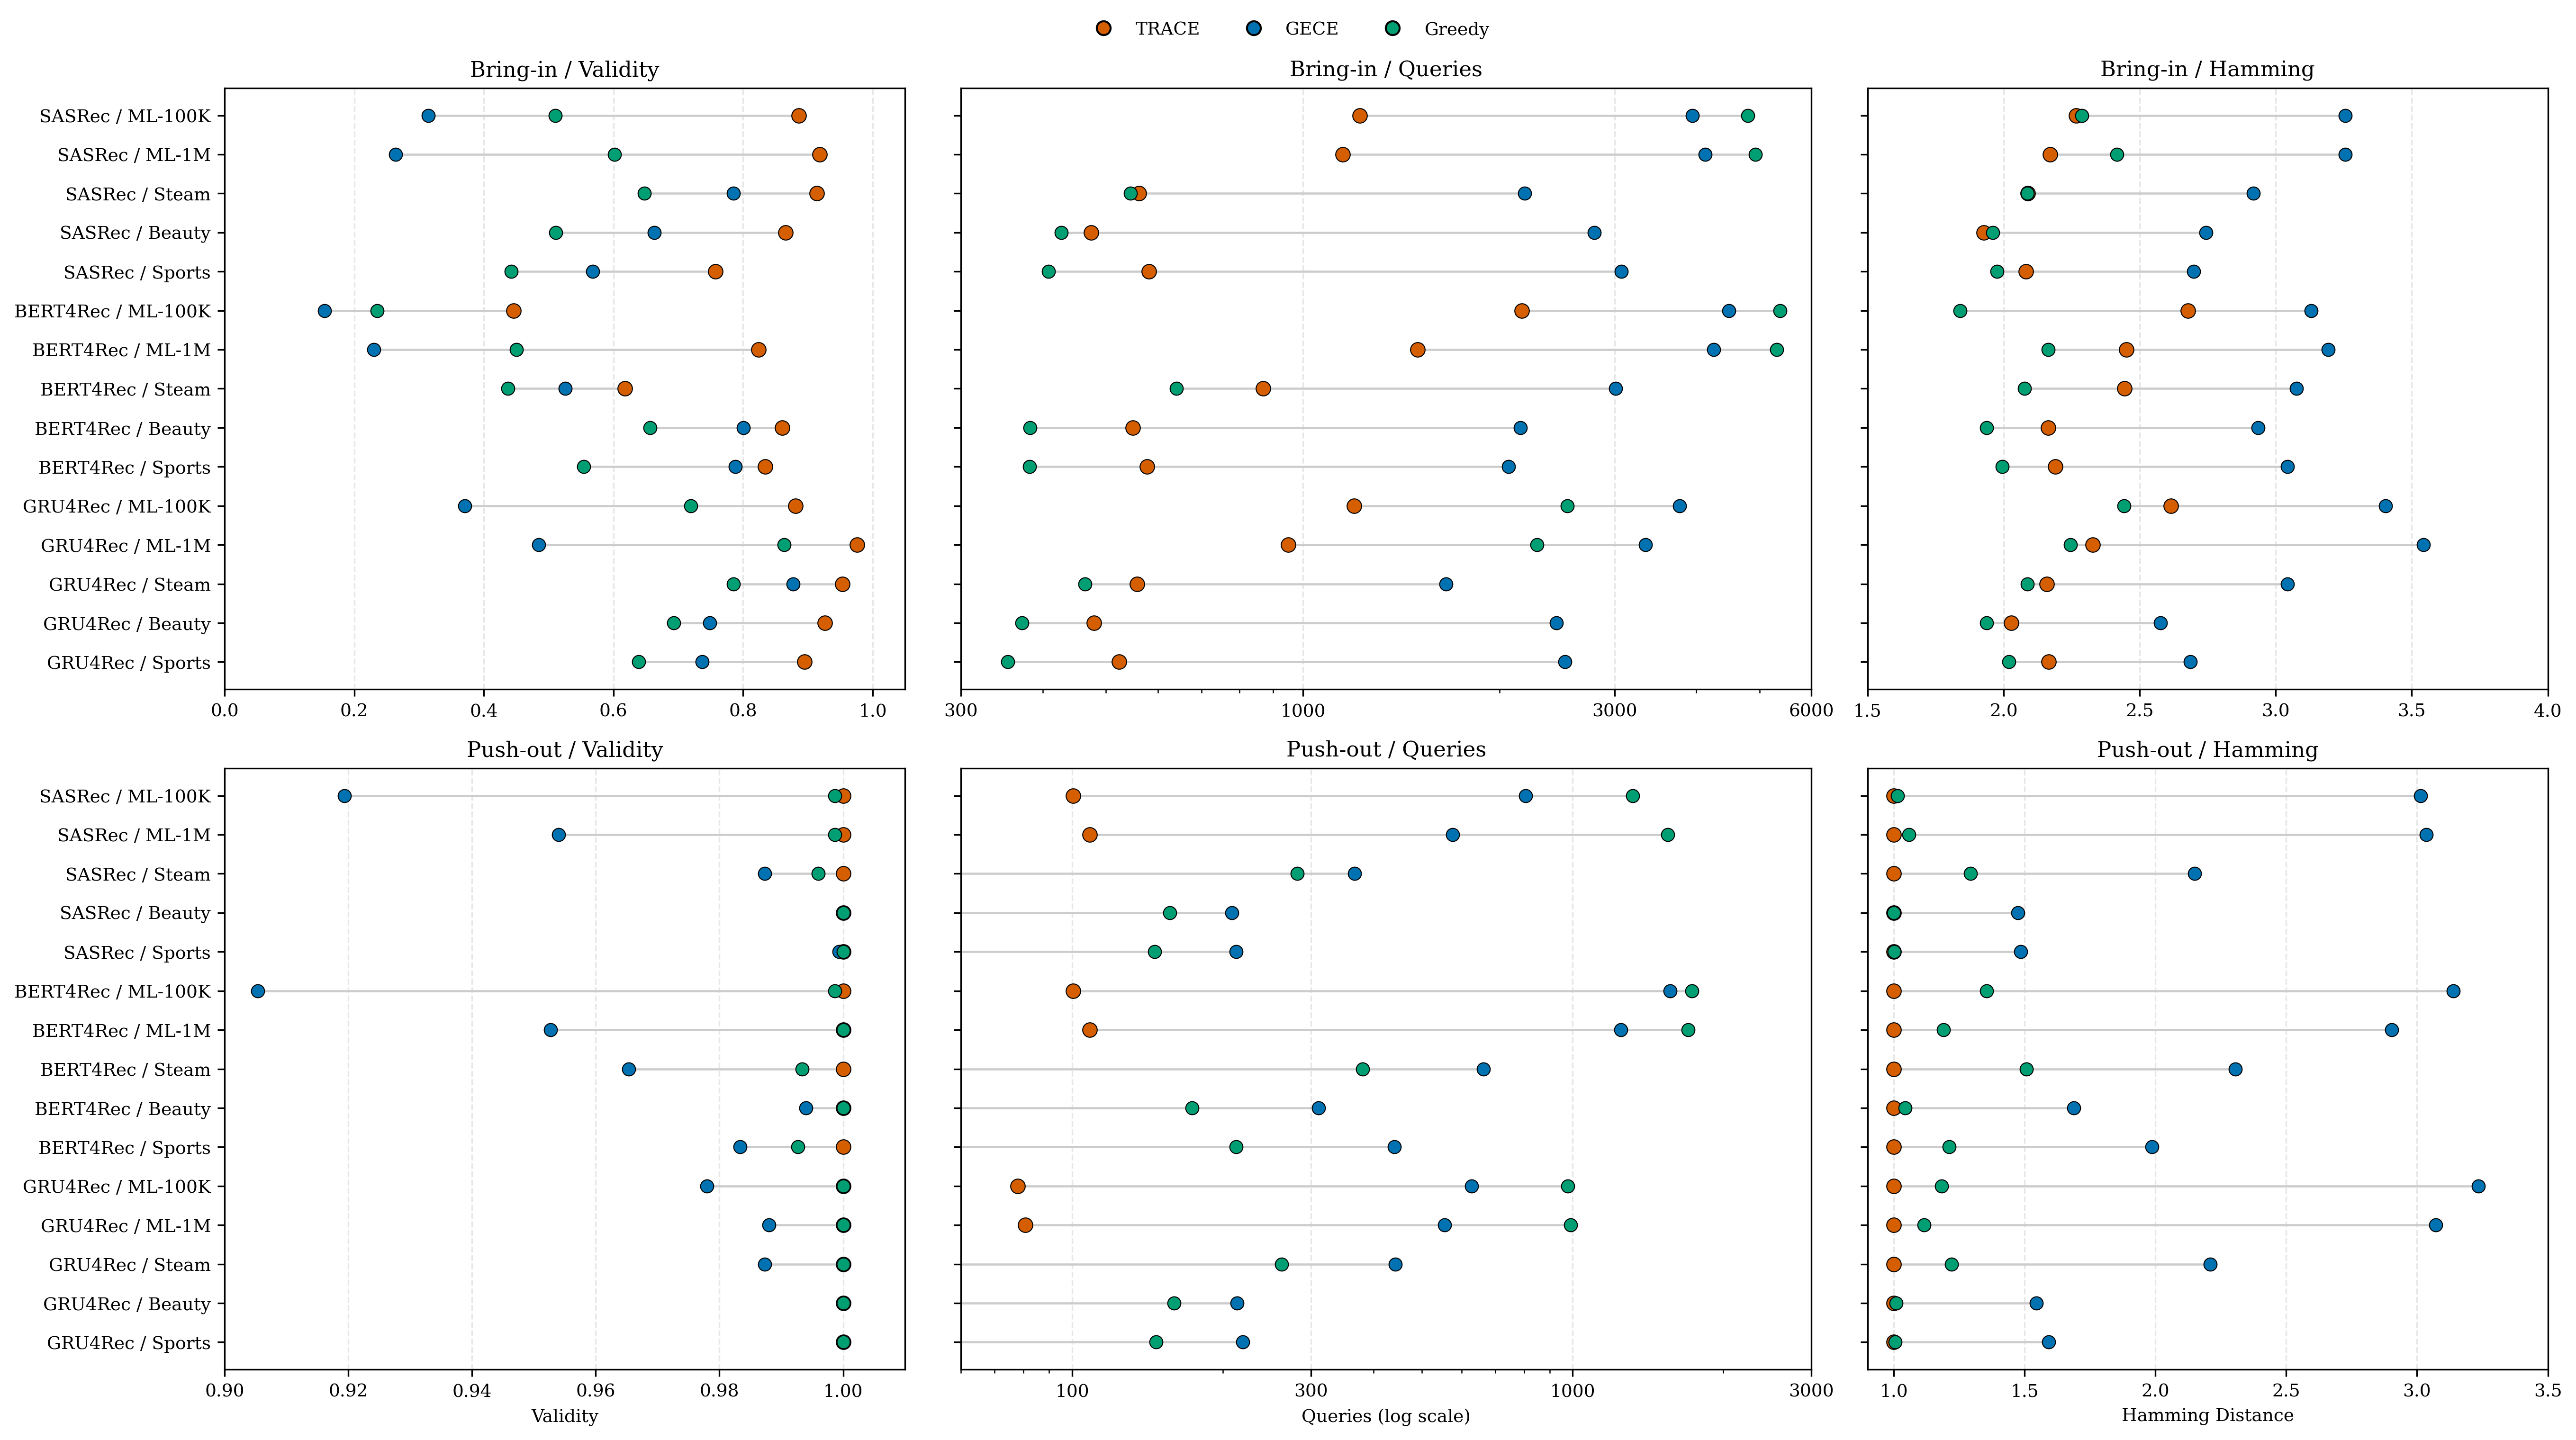

In [4]:
display(Image(filename=str(FIG_DIR / 'fig_trace_gece_greedy_triplet_combined.png'), width=1000))

### 3.2 $\Delta$NLL (Table 3)

$\Delta$NLL = conditional mean (over valid users) of the sequence NLL difference between counterfactual and original. Lower is better; negative means the counterfactual is **more** natural than the original under the backbone. Cells show mean $\pm$ std across seeds {42, 43, 44}. TRACE is lower than GECE on every one of the 30 (model, dataset, task) combinations, all significant at $p<0.05$ (paired bootstrap mean-difference test over matched valid users).

In [5]:
def _fmt_cell(pair):
    mean, std = pair
    return f'{mean:.4f} \u00b1 {std:.4f}'

def _delta_nll_df(task_idx, task_label):
    rows = P['delta_nll_main']['rows']
    datasets = P['delta_nll_main']['datasets']
    data = []
    for r in rows:
        data.append([r['model'], r['method']] + [_fmt_cell(r[d][task_idx]) for d in datasets])
    df = pd.DataFrame(data, columns=['Model', 'Method', *datasets])
    display(Markdown(f'**{task_label}**'))
    display(df)

_delta_nll_df(0, '$\\Delta$NLL &mdash; bring-in')
_delta_nll_df(1, '$\\Delta$NLL &mdash; push-out')

**$\Delta$NLL &mdash; bring-in**

,Model,Method,ML-100K,ML-1M,Steam,Beauty,Sports
0,SASRec,GECE,0.6469 ± 0.0290,0.5815 ± 0.0261,2.2039 ± 0.0868,2.5760 ± 0.0361,1.8099 ± 0.0518
1,SASRec,TRACE,0.1691 ± 0.0055,0.1285 ± 0.0059,0.3130 ± 0.0184,0.6557 ± 0.0222,0.2614 ± 0.0369
2,BERT4Rec,GECE,0.2570 ± 0.0214,0.2692 ± 0.0385,1.9062 ± 0.0549,3.8713 ± 0.0962,2.4530 ± 0.0500
3,BERT4Rec,TRACE,0.0365 ± 0.0042,0.0132 ± 0.0047,0.0397 ± 0.0236,1.9738 ± 0.1574,0.4458 ± 0.0267
4,GRU4Rec,GECE,0.4750 ± 0.0047,0.5931 ± 0.0061,2.1749 ± 0.0521,2.7387 ± 0.0983,2.2052 ± 0.0715
5,GRU4Rec,TRACE,0.1494 ± 0.0094,0.1686 ± 0.0062,0.2488 ± 0.0568,1.2661 ± 0.0413,0.6179 ± 0.0399


**$\Delta$NLL &mdash; push-out**

,Model,Method,ML-100K,ML-1M,Steam,Beauty,Sports
0,SASRec,GECE,0.0692 ± 0.0089,0.0253 ± 0.0095,1.1370 ± 0.0967,0.4033 ± 0.0336,0.4650 ± 0.0534
1,SASRec,TRACE,-0.0249 ± 0.0003,-0.0206 ± 0.0005,-0.3447 ± 0.0117,-0.3857 ± 0.0182,-0.4503 ± 0.0126
2,BERT4Rec,GECE,0.2458 ± 0.0083,0.2171 ± 0.0163,2.3405 ± 0.1098,1.3037 ± 0.1615,2.5953 ± 0.0449
3,BERT4Rec,TRACE,-0.0355 ± 0.0010,-0.0329 ± 0.0005,-0.3905 ± 0.0326,-0.0557 ± 0.1281,-0.2923 ± 0.0148
4,GRU4Rec,GECE,0.1772 ± 0.0148,0.2275 ± 0.0073,1.8538 ± 0.0351,0.6590 ± 0.0134,0.6017 ± 0.0158
5,GRU4Rec,TRACE,-0.0354 ± 0.0008,-0.0214 ± 0.0009,-0.2513 ± 0.0138,-0.1268 ± 0.0545,-0.4709 ± 0.0048


## 4. Ablation studies

The TRACE pipeline is dissected cumulatively: `Naive` = beam structure only (width 1, context-top-$k$ shortlist); `+Beam` widens the beam to 5; `+Influence` adds leave-one-out position scoring; `Full TRACE` adds the target-NN / source-NN retriever. All four variants share the same backbone and query budget.

In [6]:
def _ablation_validity_df():
    a = P['ablation_bringin_validity']
    data = []
    for r in a['rows']:
        data.append([r['variant']] + [f'{m:.1f} \u00b1 {s:.1f}' for m, s in r['values']])
    return pd.DataFrame(data, columns=['Variant', *a['combos']])

display(Markdown('### 4.1 Bring-in validity (%), higher is better (Table 4)'))
display(_ablation_validity_df())
display(Markdown('_Significance:_ Full > each of {Naive, +Beam, +Influence} at $p<0.01$ on all three combos.'))

### 4.1 Bring-in validity (%), higher is better (Table 4)

,Variant,SASRec / ML-100K,BERT4Rec / ML-1M,GRU4Rec / Steam
0,Naive,56.7 ± 1.6,56.4 ± 2.7,63.7 ± 2.5
1,+Beam,60.5 ± 0.9,59.4 ± 2.1,78.4 ± 2.4
2,+Influence,57.0 ± 0.2,60.5 ± 2.1,76.1 ± 1.5
3,Full TRACE,88.6 ± 1.0,82.4 ± 1.1,95.3 ± 0.3


_Significance:_ Full > each of {Naive, +Beam, +Influence} at $p<0.01$ on all three combos.

In [7]:
def _ablation_pushout_df(metric_key, label):
    a = P['ablation_pushout_efficiency']
    data = []
    for r in a['rows']:
        data.append([r['variant']] + [f'{m:.3f} \u00b1 {s:.3f}' for m, s in r[metric_key]])
    df = pd.DataFrame(data, columns=['Variant', *a['combos']])
    display(Markdown(f'### 4.2 Push-out {label} (Table 5)'))
    display(df)

_ablation_pushout_df('Q', 'Queries (lower is better)')
_ablation_pushout_df('delta_nll', '$\\Delta$NLL (lower is better)')
display(Markdown(P['ablation_pushout_efficiency']['notes']))

### 4.2 Push-out Queries (lower is better) (Table 5)

,Variant,SASRec / ML-100K,BERT4Rec / ML-1M,GRU4Rec / Steam
0,Naive,452.875 ± 2.404,508.649 ± 5.223,70.695 ± 2.994
1,+Beam,452.875 ± 2.404,508.649 ± 5.223,70.695 ± 2.994
2,+Influence,100.574 ± 0.338,108.521 ± 0.745,44.409 ± 0.616
3,Full TRACE,123.389 ± 0.310,131.072 ± 0.784,67.253 ± 0.815


### 4.2 Push-out $\Delta$NLL (lower is better) (Table 5)

,Variant,SASRec / ML-100K,BERT4Rec / ML-1M,GRU4Rec / Steam
0,Naive,0.128 ± 0.003,0.028 ± 0.001,0.087 ± 0.016
1,+Beam,0.128 ± 0.003,0.028 ± 0.001,0.087 ± 0.016
2,+Influence,-0.025 ± 0.000,-0.033 ± 0.000,-0.251 ± 0.014
3,Full TRACE,-0.025 ± 0.000,-0.033 ± 0.000,-0.251 ± 0.014


Per-variant runs use run_tag=ablation-<variant>. Variants are cumulative: naive -> +beam -> +influence -> full.

## 5. Significance summary

Paired tests over the 15 (model, dataset) cells. Bring-in / push-out / Greedy / GECE pairings are collapsed below.

In [8]:
def _flatten_sig(sig):
    rows = []
    for pair, entry in sig.items():
        if isinstance(entry, str):
            rows.append([pair, '', entry])
        else:
            for metric, verdict in entry.items():
                rows.append([pair, metric, verdict])
    return pd.DataFrame(rows, columns=['Comparison', 'Metric', 'Verdict'])

display(_flatten_sig(P['significance_summary']))

,Comparison,Metric,Verdict
0,bring_in_trace_vs_gece,validity,15/15 sig
1,bring_in_trace_vs_gece,queries,15/15 sig
2,bring_in_trace_vs_gece,hamming,15/15 sig
3,bring_in_trace_vs_greedy,validity,15/15 sig
4,bring_in_trace_vs_greedy,queries,13/15 sig
5,bring_in_trace_vs_greedy,hamming,9/15 sig
6,push_out_trace_vs_gece,validity,11/15 sig
7,push_out_trace_vs_gece,queries,15/15 sig lower
8,push_out_trace_vs_gece,hamming,15/15 sig lower
9,push_out_trace_vs_greedy,queries,15/15 sig lower


## 6. Qualitative case studies

Three hand-picked bring-in users illustrate what TRACE does well, what $K_{\max}{=}5$ enables, and when the proposal bottleneck bites.

In [9]:
for case in P['case_studies']:
    display(Markdown(f'### Case {case["id"]} &mdash; {case["title"]}'))
    for k, v in case.items():
        if k in ('id', 'title'):
            continue
        if isinstance(v, list):
            display(Markdown(f'- **{k}:**\n  - ' + '\n  - '.join(map(str, v))))
        elif isinstance(v, dict):
            display(Markdown(f'- **{k}:** ' + ', '.join(f'`{kk}={vv}`' for kk, vv in v.items())))
        else:
            display(Markdown(f'- **{k}:** {v}'))

### Case A &mdash; Non-movie domain head-to-head (SASRec / Steam / User 58370)

- **setting:** bring-in

- **original_tail:**
  - Thomas Was Alone (Indie)
  - The Dwarves (RPG)
  - Battleborn (Action)
  - Clicker Heroes (Adventure/Casual/Free to Play/Indie/RPG/Simulation/Strategy)

- **edits:**
  - The Dwarves -> Fallout 4
  - Battleborn -> DayZ

- **recommendation_change:** Grand Theft Auto V -> Rust

- **trace:** `delta=2`, `queries=313`, `valid=True`

... (10 outputs left out)

- **original_recommendation:** Almost Famous

- **target_item:** Small Time Crooks

- **trace:** `delta=0`, `queries=1060`, `valid=False`

- **interpretation:** Target item has 369 ratings (<< success-instance mean 998). Long-tail target -> sparse embedding neighborhood -> target-NN shortlist misses valid candidates.

## 7. Hyperparameters & dataset statistics

Section 0 above exposes the full pipeline via `make` targets; `README.md` has the equivalent shell commands. The values actually used in the paper are listed below.

In [10]:
display(Markdown('### Hyperparameters actually used in the paper'))
display(pd.Series(P['hyperparameters']).to_frame('value'))
display(Markdown('### Dataset statistics'))
display(pd.DataFrame(P['datasets']).T)

### Hyperparameters actually used in the paper

,value
query_budget_Q,10000
edit_budget_K_max,5
n_eval_users,500
seeds,"[42, 43, 44]"
beam_width_B,5
k_context,6
k_target_nn,3
k_source_nn,3
shortlist_size,12
rank_range_bring_in,"[2, 50]"


### Dataset statistics

,users,items
ml-100k,943,1349
ml-1m,6040,3416
steam,334536,13046
beauty,22363,12101
sports,35598,18357
